# PYCAVI ZP Calibration

This notebook will calibrate the swarped frame created in previous steps, so the units of the image will be in erg/s/cm$^2$ instead of e-/s. To achieve this, the notebook will download photometry of the observed field from either SDSS (astroquery.SDSS) or Skymapper (https://skymapper.anu.edu.au/) to compare and calculate the conversion factor required to obtained the desired physical units. <br>
From the final product one should be able to obtain AB magnitudes of the stars directly from the frame, as the headers store the parameters used for the photometry together with the zero points to convert to magnitudes.


## About the filters
Skymapper uses filters slightly different with respect the Sloan filters used in OmegaCam. To achieve a better comversion between both set of filters, the former ones are transformed to Sloan magnitudes using the color conversion published in SkyMapper DR1 paper, Fig 17 (https://ui.adsabs.harvard.edu/abs/2018PASA...35...10W/abstract).<br>
A table with different colors for different bandpasses is publicly available at https://skymapper.anu.edu.au/filter-transformations/, which could be use instead of the transformation from the plots (not implemented in the current version).

In the case of the NB659 filter, the calibration is based on the color-color relation for r-i and r-NB published in the VPHASp paper published by Drew et al, 2014, Table 4 (https://ui.adsabs.harvard.edu/abs/2014MNRAS.440.2036D/abstract). As VPHAS data is published in Vega system, the color-color relation was corrected with the zero points for the respective filters so it will be in AB system during the calibration process.


## About the calibration process

The calibration process is governed by the ZPCalibration class found in pycavi_zpcal.py file. The flow of the class is as follow:

- Check for the parents image to get the airmass and gain of each one. This information will be inherited by the calibrated frame.
### SDSS Calibration
- Download data from SDSS DR17 using the astroquery.SDSS class to query the STAR tables.
### Skymapper calibration
- Download the data from Skymapper with a cone search centered at the position defined by the CRVAL headers of the frame and a radius of 0.7 degrees. The raw data will be cleaned to keep only the best sources (skymapper flags and nimaflags = 0) and most likely stars (class_star > 0.9). Only the bands sm g, r, i and z will be transformed to SDSS magnitudes and saved in the final (clean) catalogue.
- Perform aperture photometry on the input frame based on the position of the stars from the clean Skymapper catalogue.
- Computes the ZP (in magnitudes) via minimization of the differences in magnitudes m$_\mathrm{sm}$ - m$_\mathrm{raw}$ in the case of the filters g, r, i and z. For NB it minimizes the differences in magnitude m$_\mathrm{r}$ - m$_\mathrm{raw}$ versus m$_\mathrm{r}$ - m$_\mathrm{i}$.
- Computes the conversion factor between e-/s (raw units) and 10**-15 erg/s/cm$^2$/arcsec$^2$ (desired physical units).
- Computes the ZP required to go directly to AB magnitudes from the calibrated frame.
- Update the headers and data of frame fits accordlingly.


## About the check of calibration

Once the calibration process of the frame is finished, the script calls SExtractor to perform photometry on the frame. Sources between Skymapper and SExtractor are cross-matched to compared their magnitudes. Check plots are created to observe how well the calibration went.

In [1]:
import os
import sys

import logging
import warnings

import numpy as np
import pandas as pd

from astropy.io import fits
from astropy.io.fits.verify import VerifyWarning

# we suppress FITS verify warnings
warnings.filterwarnings('ignore', 
                        category=UserWarning)

sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production
from pycavi import pycavi_tools

from pycavi.pycavi_zpcal import ZPCalibration, plot_calibration_check_zpcal, get_files_dict
from pycavi import pycavi_instrument
from pycavi import pycavi_astromatic_tools
from pycavi.pycavi_astromatic_tools import get_swarp_lists_dict


This will be executed when the package is imported.


In [2]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
print(config_dir)

config = pycavi_tools.read_pycavi_config(config_dir)
instrument = config['Provenance']['instrument'].lower()
observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

# Should read the instrument configuration file. This ensure
# proper keyword parsing.
#
instrument = pycavi_instrument.Instrument(config_dir=config_dir, instrument=instrument)

log_file_zpcal = log_dir + "/pymeffpp_zpcal.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_zpcal),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['swarp_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
images_to_calibrate = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        images_to_calibrate.append(zpcal_dict[observation_tags[i]][j])

for i in range(len(images_to_calibrate)):
    logging.info("index: {} -- file: {}".format(i, images_to_calibrate[i]))



2024-10-21 15:19:13,325:INFO:index: 0 -- file: /Users/fselman/Pictures/OCAM/Multi//science/CP_Pup/Swarp_dir/CP_Pup_r_SDSS.coadd.fits
2024-10-21 15:19:13,326:INFO:index: 1 -- file: /Users/fselman/Pictures/OCAM/Multi//science/M67/Swarp_dir/M67_g_SDSS.coadd.fits
2024-10-21 15:19:13,327:INFO:index: 2 -- file: /Users/fselman/Pictures/OCAM/Multi//science/M67/Swarp_dir/M67_r_SDSS.coadd.fits
2024-10-21 15:19:13,328:INFO:index: 3 -- file: /Users/fselman/Pictures/OCAM/Multi//science/M67/Swarp_dir/M67_NB_659.coadd.fits
2024-10-21 15:19:13,328:INFO:index: 4 -- file: /Users/fselman/Pictures/OCAM/Multi//std/SA101/Swarp_dir/SA101_g_SDSS.coadd.fits
2024-10-21 15:19:13,329:INFO:index: 5 -- file: /Users/fselman/Pictures/OCAM/Multi//std/SA101/Swarp_dir/SA101_r_SDSS.coadd.fits
2024-10-21 15:19:13,330:INFO:index: 6 -- file: /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/SA98_NB_659.coadd.fits


/Users/fselman/Software/Pycavi/notebooks/../config/
config_dir: /Users/fselman/Software/Pycavi/notebooks/../config/ instrument: omegacam


2024-10-21 18:00:32,132:INFO:Starting to work on frame SA98_NB_659.coadd.fits
2024-10-21 18:00:32,133:INFO:Folder already exists
2024-10-21 18:00:32,135:INFO:Copying /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/SA98_NB_659.coadd.fits --> /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/../Calibration_dir//SA98_NB_659.coadd.fits


/Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir


2024-10-21 18:00:33,524:INFO:ZPCalibration: init: reading frame
2024-10-21 18:00:33,556:INFO:self.data.shape: (18056, 17925)
2024-10-21 18:00:33,559:INFO:ZPCalibration: Input data array with do_not_scale_image_data=True <data_1d>: 6.111E-19


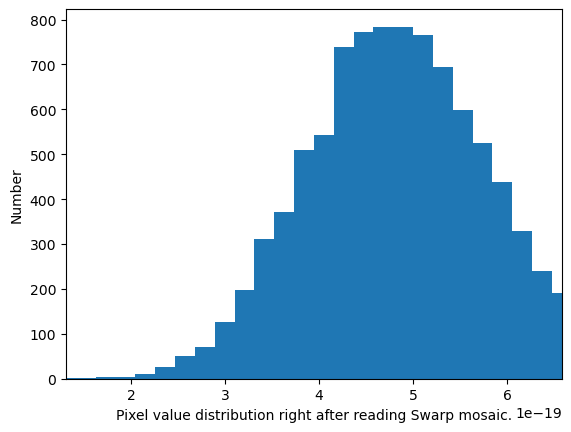

2024-10-21 18:00:33,725:INFO:ZPCalibration: plate_scale:  0.213 (sx:  0.213 - sy:  0.213) arcsec/pix
2024-10-21 18:00:33,726:INFO:ZPCalibration: init: loading wcs info from frame
Set DATE-END to '2014-12-02T07:56:01.089' from MJD-END'. [astropy.wcs.wcs]
2024-10-21 18:00:34,151:WARNING:FITSFixedWarning: 'datfix' made the change 'Set DATE-OBS to '2014-12-02T07:52:41.089' from MJD-OBS.
Set DATE-END to '2014-12-02T07:56:01.089' from MJD-END'.


OBJECT: STD,ZEROPOINT


2024-10-21 18:00:34,154:INFO:get_avg_gain_from_frame: reading original files used by Swarp to determine gains.
2024-10-21 18:00:34,888:INFO:get_avg_gain_from_frame: avg_gain: 2.147812
2024-10-21 18:00:34,889:INFO:get_avg_airmass_from_frame: reading original files used by Swarp to determine airmass.
2024-10-21 18:00:34,892:INFO:get_avg_airmass_from_frame: airmass for image OMEGA.2014-12-02T07:52:41.089_pre_wcs.fits : 1.1405
2024-10-21 18:00:34,893:INFO:get_avg_exptimes: read exposure time from files used by Swarp.
2024-10-21 18:00:34,896:INFO:Exposure time for image OMEGA.2014-12-02T07:52:41.089_pre_wcs.fits : 200.0 seconds
2024-10-21 18:00:34,897:INFO:get_avg_exptime_from_frames: average exposure time of frames : 200
2024-10-21 18:00:34,898:INFO:get_avg_exptime_from_frames: total exposure time of frames : 200
2024-10-21 18:00:34,899:INFO:Query used:

2024-10-21 18:00:34,900:INFO:
SELECT dr3.source_id, dr3.ra, dr3.dec, classprob_dsc_combmod_star,
gspc.source_id, gspc.u_sdss_mag, gspc.u_

gspc.u_sdss_mag, gspc.u_sdss_flux, gspc.u_sdss_flux_error, gspc.g_sdss_mag, gspc.g_sdss_flux, gspc.g_sdss_flux_error, gspc.r_sdss_mag, gspc.r_sdss_flux, gspc.r_sdss_flux_error, gspc.i_sdss_mag, gspc.i_sdss_flux, gspc.i_sdss_flux_error, gspc.z_sdss_mag, gspc.z_sdss_flux, gspc.z_sdss_flux_error


2024-10-21 18:00:45,512:INFO:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
SOURCE_ID
ra
dec
classprob_dsc_combmod_star
source_id
u_sdss_mag
u_sdss_flux
u_sdss_flux_error
g_sdss_mag
g_sdss_flux
g_sdss_flux_error
r_sdss_mag
r_sdss_flux
r_sdss_flux_error
i_sdss_mag
i_sdss_flux
i_sdss_flux_error
z_sdss_mag
z_sdss_flux
z_sdss_flux_error


2024-10-21 18:00:45,830:INFO:create_ds9_reg_file: DS9 region file '/Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/../Calibration_dir//gaia3_qry_STD,ZEROPOINT.reg' created successfully.
2024-10-21 18:00:45,831:INFO:add_secondary_filter_to_df: reading data from /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/../Calibration_dir//gaia3_qry_STD,ZEROPOINT_clean.csv


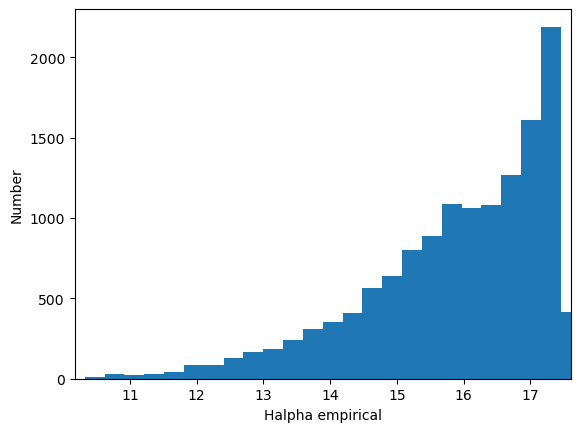

2024-10-21 18:00:46,275:INFO:add_secondary_filter_to_df: filter: NB_659 added to df
2024-10-21 18:00:46,277:INFO:calibrators_apertures: creating aperture object
2024-10-21 18:00:46,279:INFO:do_phot: doing aperture photometry on frame.
2024-10-21 18:00:57,468:INFO:do_phot: phot_disk_area in pixels: 1725.8558829759145
2024-10-21 18:00:57,469:INFO:do_phot: estimating backgrounds.
2024-10-21 18:00:59,070:INFO:do_phot: number of objects: 13894
2024-10-21 18:01:08,712:INFO:do_phot: subtracting backgrounds.


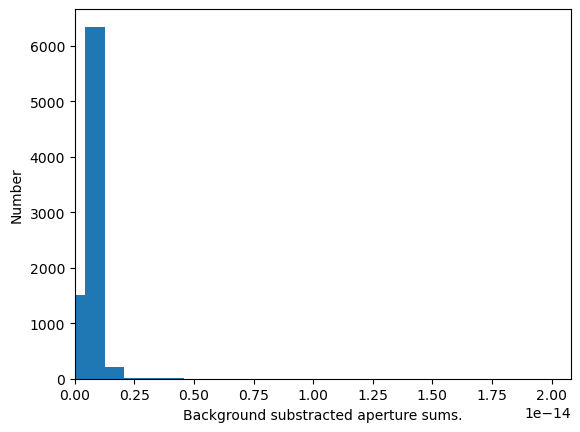

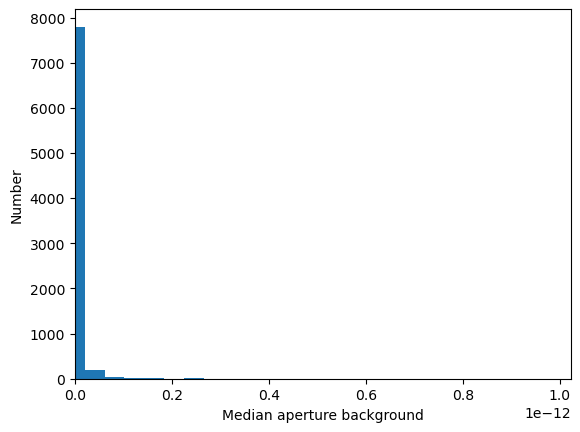

2024-10-21 18:01:08,979:INFO:do_phot: Adding column with raw magnitudes to data frame.
2024-10-21 18:01:08,980:INFO:do_phot: MAGZP found in headers with value: -21.476
2024-10-21 18:01:08,983:INFO:do_phot: appending column frame_ab_NB_659 to file /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/../Calibration_dir//gaia3_qry_STD,ZEROPOINT_clean.csv


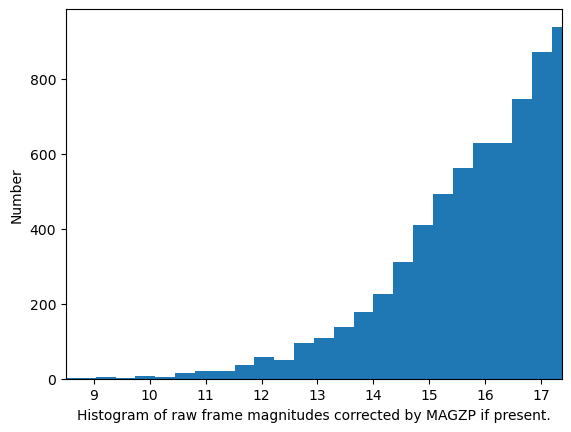

2024-10-21 18:01:09,360:INFO:do_phot: Creating a PSF model to extract morphological parameters of star...
/Users/fselman/anaconda3/lib/python3.11/site-packages/astropy/modeling/functional_models.py:513: RuntimeWarning: invalid value encountered in divide
  dg_dA = g / amplitude
2024-10-21 18:01:52,815:INFO:do_phot: **** median fwhm: 1.1150738778704001 ellipticity: 3.575435488867296e-05  theta: -6.730363775403381e-13
2024-10-21 18:01:52,822:INFO:do_phot: Done.
2024-10-21 18:01:52,999:INFO:get_zp_from_df: number of good mags: 6753
2024-10-21 18:01:53,004:INFO:sigma_clip2: number of good data points: 6525
2024-10-21 18:01:53,019:INFO:sigma_clip2: number of good data points: 6525
2024-10-21 18:01:53,026:INFO:sigma_clip2: number of good data points: 6525
2024-10-21 18:01:53,027:INFO:df zero point: 0.0
2024-10-21 18:01:53,028:INFO:ZPCalibration: MAGZP found in headers with value: -21.476
2024-10-21 18:01:53,028:INFO:ZPCalibration: zp: -21.476 to go from DN in current file to mags
2024-10-21 

[18.6148 21.9151 16.1193 ... 18.6711 18.3106 19.7159]
[16.1193 17.2976 17.271  ... 16.8721 15.7651 17.4954]
[16.1193 17.2976 17.271  ... 16.8721 15.7651 17.4954]
[16.1193 17.2976 17.271  ... 16.8721 15.7651 17.4954]


2024-10-21 18:02:00,470:INFO:get_orig_sky_levels: sky 1/1: OMEGA.2014-12-02T07:52:41.089_pre_wcs.fits
2024-10-21 18:02:00,477:INFO:get_orig_sky_levels: sky 1/1: 0.234 +- 0.016
2024-10-21 18:02:00,477:INFO:get_orig_sky_levels: Done.
2024-10-21 18:02:00,480:INFO:get_mag_sky: surface brightness of sky in magnitudes per arcsec^2
2024-10-21 18:02:00,480:INFO:get_mag_sky: self.mean_sky: 5.486219125912319e-19
2024-10-21 18:02:00,481:INFO:get_mag_sky: magsky: 20.821 mags/arcsec^2
2024-10-21 18:02:00,482:INFO:get_std_dev_mag_sky: standard deviation of sky in magnitudes per arcsec^2
2024-10-21 18:02:13,173:INFO:get_std_dev_mag_sky: std_dev: 1.173e-17 ADUs
2024-10-21 18:02:13,180:INFO:mag_sky_std_dev: 17.496 mags/arcsec^2
2024-10-21 18:02:13,182:INFO:get_moon_from_frames: read files used by Swarp to read calculate lunar data.
2024-10-21 18:02:13,183:INFO:get_moon_from_frames: Moon for 1/1: OMEGA.2014-12-02T07:52:41.089_pre_wcs.fits
2024-10-21 18:02:13,189:INFO:get_moon_from_frames: DATE-OBS: DATE

['60.A-9038(A)']
update_frame: before update <data_1d>: 6.111E-19


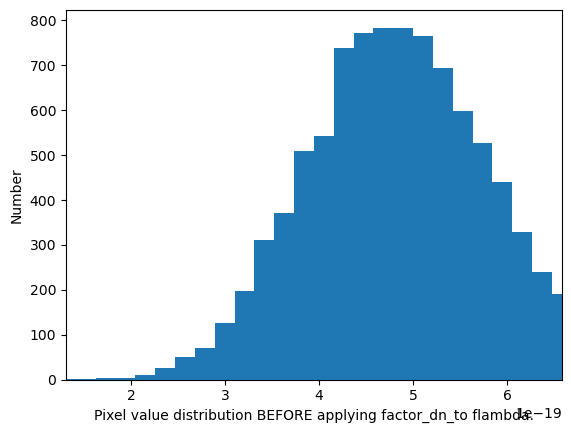

2024-10-21 18:02:13,532:INFO:update_frame: key ESO PYCAVI QC DN2FLAM in headers with value 2.34225631790593e-18
2024-10-21 18:02:13,532:INFO:update_frame: multiplyimg frame data by 1.0000792559816964 (should be near 1.0)
2024-10-21 18:02:13,533:INFO:dn2flambda: 1.0000792559816964   factor: 1.0000792559816964    old_factor: 2.34225631790593e-18
2024-10-21 18:02:15,043:INFO:update_frame: new value HIERARCH ESO PYCAVI QC DN2FLAM: 2.34244e-18
2024-10-21 18:02:15,046:INFO:update_frame: reordering headers...
2024-10-21 18:02:17,203:INFO:update_frame: done, headers have been reordered successfully n_hierarch: 56 n_nonhierarch: 69.


update_frame: after update <data_1d>: 6.112E-19


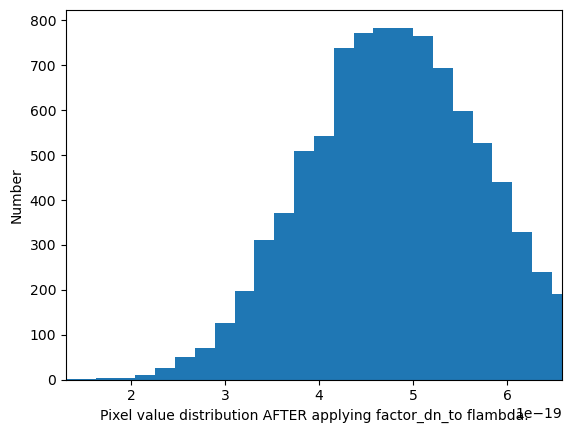

2024-10-21 18:02:18,525:INFO:update_frame: Image updated correctly
2024-10-21 18:02:18,527:INFO:ZPCalibration: all done. Celebrate with a cup of coffe :)
2024-10-21 18:02:18,527:INFO:zpcal.calibrationdir: /Users/fselman/Pictures/OCAM/Multi//std/SA98/Swarp_dir/../Calibration_dir/
2024-10-21 18:02:18,528:INFO:-------Done-------


In [5]:
# Here we do the calibration of each file
#

mag_min = 10.5  # minimum magnitude to consider from skymapper catalogue when determining zero point
mag_max = 18.5  # maximum magnitude to consider from skymapper catalogue when determining zero point
aperture_radius = 5.0  # aperture in arcsec when performing aperture photometry on frame 
ap_sky_r1 = 6.0 # annulus inner radius to determine background around stars during aperture photometry
ap_sky_r2 = 9.0 # annulus outer radius to determine background around stars during aperture photometry
#query_calibrator = "Skymapper"  # SDSS for northern or Skymapper for southern latitudes
#query_calibrator = "SDSS"
query_calibrator = "Gaia"
query_radius=0.7
query_min_mag=10.0
query_max_mag=19.0

# See list above to select a data partition to calibrate
# For example, if the list is:
#
# index: 0 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/CP_Pup/Swarp_dir/CP_Pup_r_SDSS.coadd.fits
# index: 1 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_g_SDSS.coadd.fits
# index: 2 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_r_SDSS.coadd.fits
# index: 3 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Swarp_dir/M67_NB_659.coadd.fits
# index: 4 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_g_SDSS.coadd.fits
# index: 5 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Swarp_dir/SA101_r_SDSS.coadd.fits
# index: 6 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA98/Swarp_dir/SA98_NB_659.coadd.fits
#
# then to calibrate M67_NB_659.coadd.fits set
#
# idx_selected = [3]
#
idx_selected = [6]
for i in range(len(images_to_calibrate)):

    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue
    image = images_to_calibrate[i]
    swarp_dir = os.path.dirname(image)
    calibration_dir = swarp_dir+'/../'+config['Directories']['cal_dir_name']+'/'
    print(swarp_dir)
    logging.info("Starting to work on frame {}".format(image.split("/")[-1]))

    # This step queries a photometric database to extract positions and magnitudes
    # to be used to set the zero point of the frame. Currently only skymapper and SDSS
    # are used. Skymapper covers the southern skies and SDSS the northern one.
    #
    zpcal = ZPCalibration(image, swarp_dir, calibration_dir, observatory, instrument,
                          mag_min=mag_min, mag_max=mag_max, 
                          ap_radius=aperture_radius, ap_sky_r1=ap_sky_r1, ap_sky_r2=ap_sky_r2,
                          query_calibrator=query_calibrator, 
                          query_radius=query_radius, 
                          query_min_mag=query_min_mag, query_max_mag=query_max_mag)
    logging.info("zpcal.calibrationdir: {}".format(zpcal.calibrationdir))
    
logging.info("-------Done-------")